PLEASE REFER TO APPENDIX ON HOW TO RUN THE CODE, CHANGE THE FILE NAMES ACCORDINGLY IN ORDER FOR THE DATASETS TO BE IMPORTED ON YOUR SYSTEM. YOU CAN LOCATE THE WHEREABOUTS OF THE CSV'S BY CHECKING THE PATHWAY WHERE THE CODE IS TRYING TO IMPORT


USE localized_url function if there's an error with the imports

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [6]:
import requests
import json
import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
#ignore warnings
import warnings
warnings.filterwarnings("ignore")
import ScraperFC as sfc
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error


In [7]:
epl_stats =pd.read_csv('Data/understat_match_1524.csv')

In [8]:
epl_stats.columns

Index(['id', 'fid', 'h', 'a', 'date', 'league_id', 'season', 'h_goals',
       'a_goals', 'team_h', 'team_a', 'h_xg', 'a_xg', 'h_w', 'h_d', 'h_l',
       'league', 'h_shot', 'a_shot', 'h_shotOnTarget', 'a_shotOnTarget',
       'h_deep', 'a_deep', 'a_ppda', 'h_ppda'],
      dtype='object')

In [9]:
def nan_analysis(df):
    """
    This function takes a DataFrame and returns a DataFrame with the percentage of NaN values for each column.
    Only columns with NaN values are included in the output DataFrame.
    """
    nan_percentage = df.isna().mean() * 100
    nan_percentage = nan_percentage[nan_percentage > 0].reset_index()
    nan_percentage.columns = ['Column Name', 'Percentage of NaN Values']
    nan_percentage = nan_percentage.sort_values(by='Percentage of NaN Values', ascending=False)
    return nan_percentage
nan_analysis(epl_stats)


,Column Name,Percentage of NaN Values


In [10]:
epl_stats=epl_stats[[ 'h_xg', 'a_xg', 'h_w', 'h_d', 'h_l',
       'h_shot', 'a_shot', 'h_shotOnTarget', 'a_shotOnTarget',
       'h_deep', 'a_deep', 'a_ppda', 'h_ppda']]

In [11]:
convertible_cols,unconvertable_cols = [],[]
for col in epl_stats.columns:
    try:
        # Try converting column to numeric and then to integer
        pd.to_numeric(epl_stats[col], errors='raise').astype('Int64')
        convertible_cols.append(col)
    except:
        print(f"Column '{col}' cannot be converted to integer.")
        unconvertable_cols.append(col)
        pass  # Skip columns that can't be converted


Column 'h_xg' cannot be converted to integer.
Column 'a_xg' cannot be converted to integer.
Column 'h_w' cannot be converted to integer.
Column 'h_d' cannot be converted to integer.
Column 'h_l' cannot be converted to integer.
Column 'a_ppda' cannot be converted to integer.
Column 'h_ppda' cannot be converted to integer.


In [12]:
len(unconvertable_cols)

7

In [13]:
epl_stats[unconvertable_cols]

,h_xg,a_xg,h_w,h_d,h_l,a_ppda,h_ppda
0,0.627539,0.674600,0.2859,0.3905,0.3236,8.2188,13.8261
1,0.876106,0.782253,0.3435,0.3607,0.2958,11.8462,6.9000
2,0.604226,0.557892,0.2988,0.4337,0.2675,17.1579,6.6500
3,2.568030,1.459460,0.6422,0.2057,0.1521,9.5556,10.8800
4,1.130760,2.109750,0.1461,0.2159,0.6380,10.6250,5.7368
...,...,...,...,...,...,...,...
3415,2.231890,0.598846,0.7913,0.1508,0.0579,30.3000,14.4783
3416,5.659370,0.731254,0.9939,0.0057,0.0004,16.6000,5.0968
3417,2.067430,1.115980,0.6273,0.2206,0.1521,10.5000,13.8947
3418,2.315040,0.240159,0.8797,0.1018,0.0185,63.0000,8.0000


In [14]:
#check if the columns has a percentage sign, a percentage and / sign, or no sign:
flt,perc,div = [],[],[]
for i in unconvertable_cols:
    if epl_stats[i].astype(str).str.contains('%').any() and epl_stats[i].astype(str).str.contains('/').any():
        div.append(i)
    elif epl_stats[i].astype(str).str.contains('%').any() and not epl_stats[i].astype(str).str.contains('/').any():
        perc.append(i)
    else:
        flt.append(i)

In [15]:
import re

def extract_percentage_column(df, col):
    return df[col].str.extract(r'\((\d+)%\)')[0].astype(float)/100

In [16]:


for i in div:
    epl_stats[i] = extract_percentage_column(epl_stats, i)


In [17]:
def change_percentage_to_float(df, col):
    """
    Takes a DataFrame and column name. Extracts percentage values like '57%' and converts them to float (0.57).
    """
    return df[col].str.replace('%', '', regex=False).astype(float) / 100
# Apply the function to the specified columns
for col in perc:
    if epl_stats[col].astype(str).str.contains('%').any():
        print(f"Converting column '{col}' to float.")
        epl_stats[col] = change_percentage_to_float(epl_stats, col)
    else:
        print(f"Skipping column '{col}' — no '%' symbol found.")

In [18]:
epl_stats[perc].head(10)

""
0
1
2
3
4
5
6
7
8
9


In [19]:
epl_stats[flt]

,h_xg,a_xg,h_w,h_d,h_l,a_ppda,h_ppda
0,0.627539,0.674600,0.2859,0.3905,0.3236,8.2188,13.8261
1,0.876106,0.782253,0.3435,0.3607,0.2958,11.8462,6.9000
2,0.604226,0.557892,0.2988,0.4337,0.2675,17.1579,6.6500
3,2.568030,1.459460,0.6422,0.2057,0.1521,9.5556,10.8800
4,1.130760,2.109750,0.1461,0.2159,0.6380,10.6250,5.7368
...,...,...,...,...,...,...,...
3415,2.231890,0.598846,0.7913,0.1508,0.0579,30.3000,14.4783
3416,5.659370,0.731254,0.9939,0.0057,0.0004,16.6000,5.0968
3417,2.067430,1.115980,0.6273,0.2206,0.1521,10.5000,13.8947
3418,2.315040,0.240159,0.8797,0.1018,0.0185,63.0000,8.0000


In [20]:
#turn object columns to either float or int depending on the column
for col in convertible_cols:
    if epl_stats[col].dtype == 'object':
        try:
            # Try converting to integer first
            epl_stats[col] = pd.to_numeric(epl_stats[col], errors='raise').astype('Int64')
        except:
            # If that fails, convert to float
            epl_stats[col] = pd.to_numeric(epl_stats[col], errors='raise').astype(float)

In [21]:
drop_for_now=nan_analysis(epl_stats)['Column Name'].tolist()
drop_for_now.append('id')
dropped_df=epl_stats[drop_for_now].copy()
#remove id from the list of columns to drop
drop_for_now.remove('id')
epl_stats=epl_stats.drop(columns=drop_for_now)
nan_analysis(dropped_df)

KeyError: "None of [Index(['id'], dtype='object')] are in the [columns]"

In [ ]:
epl_stats.columns

Index(['id', 'fid', 'h', 'a', 'date', 'league_id', 'season', 'h_goals',
       'a_goals', 'team_h', 'team_a', 'h_xg', 'a_xg', 'h_w', 'h_d', 'h_l',
       'league', 'h_shot', 'a_shot', 'h_shotOnTarget', 'a_shotOnTarget',
       'h_deep', 'a_deep', 'a_ppda', 'h_ppda'],
      dtype='object')

In [ ]:
epl_stats

,h_xg,a_xg,h_w,h_d,h_l,h_deep,a_deep,a_ppda,h_ppda,Shots on target per total shots_home,Shots on target per total shots_away
0,0.627539,0.674600,0.2859,0.3905,0.3236,4,10,8.2188,13.8261,0.111111,0.444444
1,0.876106,0.782253,0.3435,0.3607,0.2958,11,2,11.8462,6.9000,0.181818,0.428571
2,0.604226,0.557892,0.2988,0.4337,0.2675,5,4,17.1579,6.6500,0.500000,0.454545
3,2.568030,1.459460,0.6422,0.2057,0.1521,5,6,9.5556,10.8800,0.421053,0.454545
4,1.130760,2.109750,0.1461,0.2159,0.6380,5,10,10.6250,5.7368,0.352941,0.636364
...,...,...,...,...,...,...,...,...,...,...,...
3415,2.231890,0.598846,0.7913,0.1508,0.0579,11,0,30.3000,14.4783,0.600000,0.250000
3416,5.659370,0.731254,0.9939,0.0057,0.0004,22,1,16.6000,5.0968,0.388889,0.750000
3417,2.067430,1.115980,0.6273,0.2206,0.1521,4,5,10.5000,13.8947,0.400000,0.466667
3418,2.315040,0.240159,0.8797,0.1018,0.0185,16,0,63.0000,8.0000,0.428571,0.666667


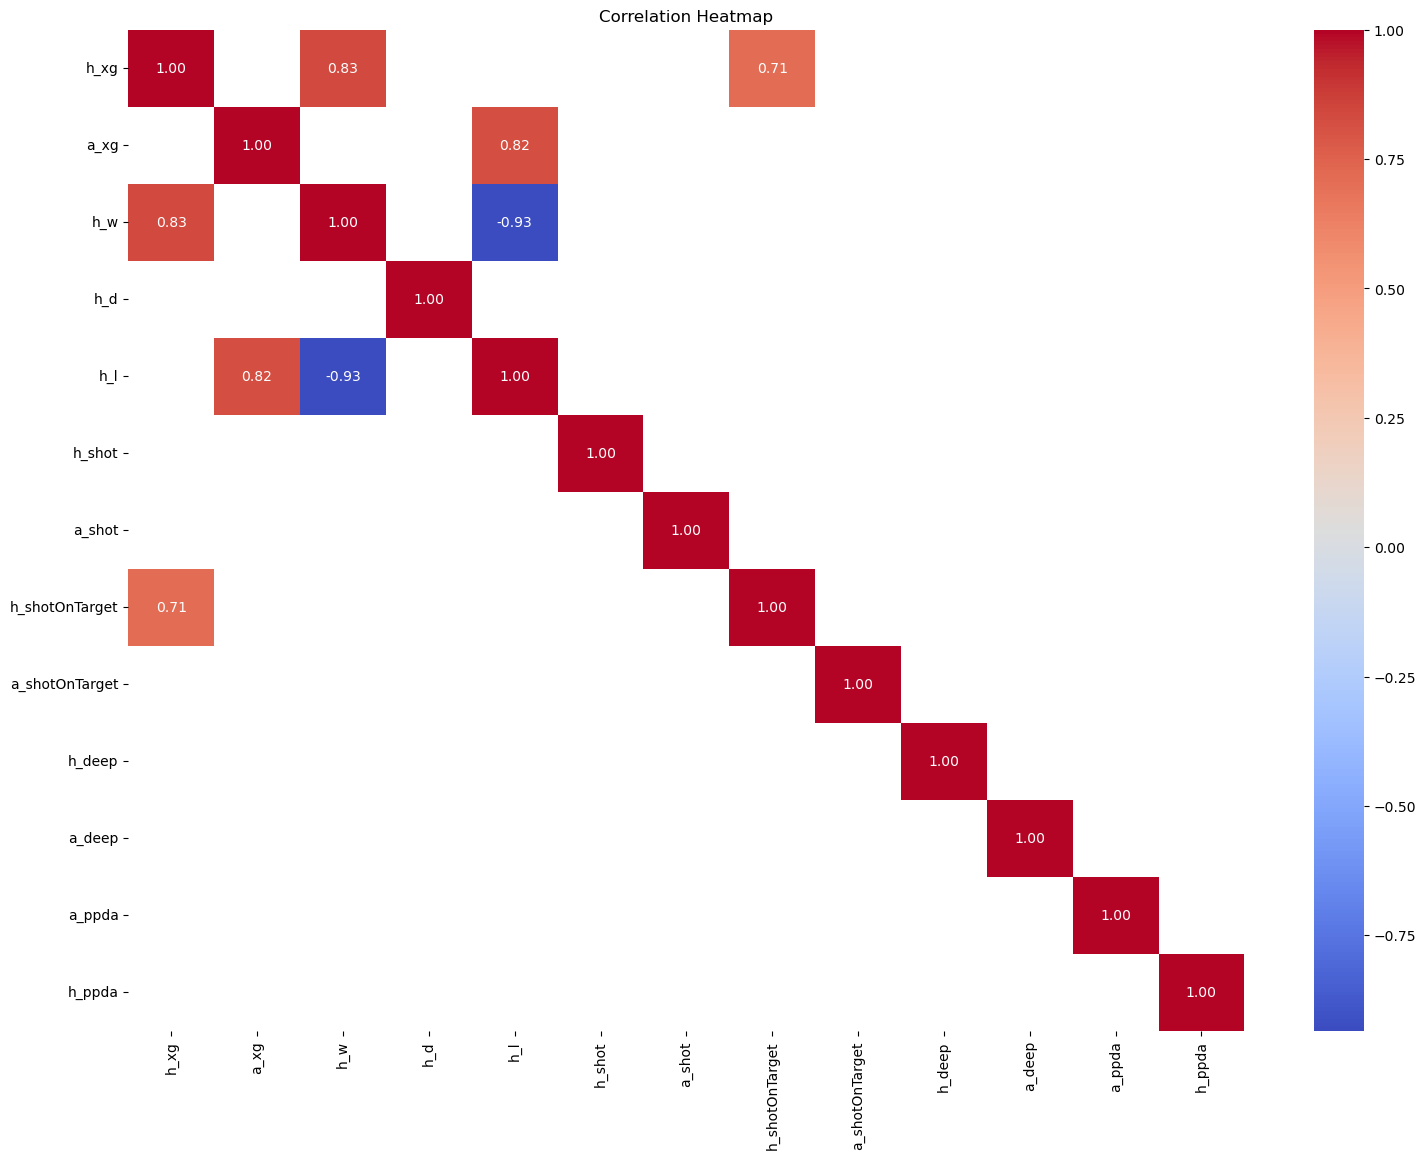

In [22]:
#correlation matrix, show only the correlation >0.7
def plot_correlation_matrix(df):
    """
    Plots a correlation matrix for the given DataFrame.
    """
    corr = df.corr()
    corr = corr[(abs(corr) > 0.7)]
    plt.figure(figsize=(18, 13))
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', cbar=True)
    plt.title('Correlation Heatmap')
    plt.show()
plot_correlation_matrix(epl_stats)

In [8]:
def safe_divide(numerator, denominator):
    denominator=denominator.replace(0, 1)


    result = numerator / denominator
    result[(numerator == 0)] = 0
    
    return result


In [9]:
epl_stats['Shots on target per total shots_home'] = safe_divide(epl_stats['h_shotOnTarget'], epl_stats['h_shot'])
epl_stats['Shots on target per total shots_away'] = safe_divide(epl_stats['a_shotOnTarget'], epl_stats['a_shot'])







#drop all the features that were engineered into new features
drop_features = ['h_shotOnTarget', 'h_shot', 'a_shotOnTarget', 'a_shot', 'h_w', 'h_l']
epl_stats.drop(columns=drop_features, inplace=True)



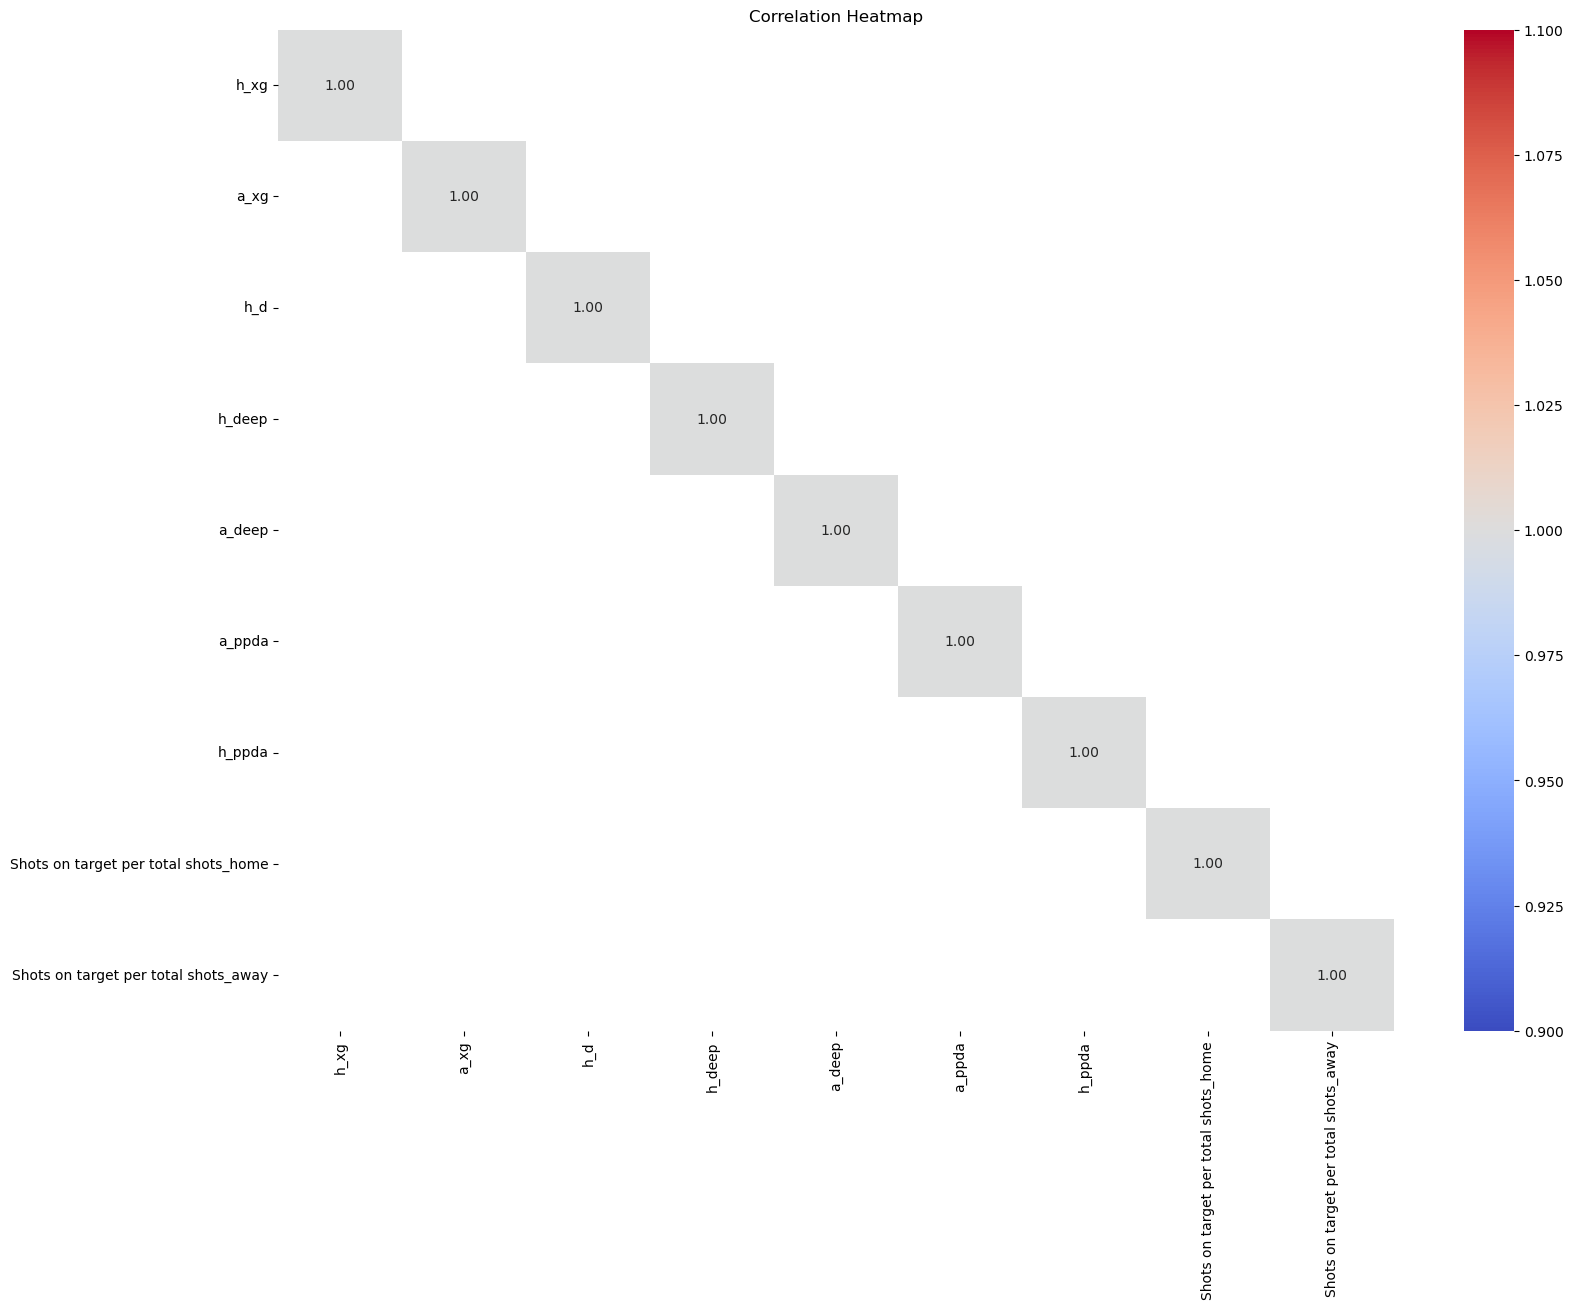

In [10]:
plot_correlation_matrix(epl_stats)

In [ ]:
epl_stats.describe()

,Expected goals_home,Corner kicks_home,Fouls_home,Shots off target_home,Throw-ins_home,Final third entries_home,Long balls_home,Crosses_home,Ground duels_home,Aerial duels_home,...,id,Blocked per shots on target_home,Blocked per shots on target_away,Shots on target per total shots_home,Shots on target per total shots_away,Hit woodwork per total shots_home,Hit woodwork per total shots_away,Shots outside box per total shots_home,Shots outside box per total shots_away,Overall game dominance
count,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,...,3.800000e+02,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000
mean,1.779184,6.123684,10.757895,5.507895,18.171053,55.855263,0.472316,0.238763,0.506553,0.510789,...,1.138610e+07,1.085179,0.980276,0.360375,0.376535,0.025042,0.022024,0.327711,0.321091,0.033539
std,0.958165,3.230456,3.463997,2.834473,5.426866,15.205630,0.122017,0.112181,0.061849,0.113015,...,1.571717e+05,1.097063,1.060162,0.147585,0.161187,0.043099,0.045800,0.132161,0.157141,0.282305
min,0.120000,0.000000,2.000000,0.000000,6.000000,17.000000,0.160000,0.000000,0.320000,0.170000,...,1.135225e+07,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.621791
25%,1.027500,4.000000,8.000000,4.000000,14.000000,46.000000,0.390000,0.170000,0.470000,0.440000,...,1.135239e+07,0.500000,0.333333,0.263158,0.258152,0.000000,0.000000,0.239524,0.222222,-0.170144
50%,1.595000,6.000000,11.000000,5.000000,18.000000,54.000000,0.460000,0.230000,0.510000,0.500000,...,1.135249e+07,0.833333,0.714286,0.357143,0.363636,0.000000,0.000000,0.333333,0.312500,0.052715
75%,2.405000,8.000000,13.000000,7.000000,21.000000,65.000000,0.550000,0.300000,0.550000,0.580000,...,1.135259e+07,1.333333,1.166667,0.454545,0.485000,0.045455,0.000000,0.417763,0.428571,0.244690
max,7.110000,17.000000,20.000000,17.000000,39.000000,108.000000,0.900000,0.690000,0.680000,0.920000,...,1.224063e+07,8.000000,9.000000,1.000000,1.000000,0.230769,0.250000,0.714286,1.000000,0.670993


In [11]:
epl_stats.to_csv("understat_epl1524_processed.csv", index=False)